# Hamiltonian dynamics, mass and adaptation

Momentum covariance is inverse(P), kinetic energy is pᵀPp/2, and position velocity is Pp. Geometry and step-size conventions must agree. Adaptation freezes before retained sampling.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
torch.set_num_threads(1)
from sampling_lab.targets import load_target
from sampling_lab.artifacts import sha256
def read(path): return json.loads((ROOT/path).read_text())
def numeric(name): return np.load(ROOT/"assets/source_data"/(name+".npz"),allow_pickle=False)
%matplotlib inline


## Independent implementation check

In [2]:
from sampling_lab.samplers import leapfrog
target=load_target("gaussian");P=target.cov;x=np.array([.2,-.8]);p=np.array([.1,-.2])
y,q,ok=leapfrog(target,x,p,.05,20,P)
z,r,ok2=leapfrog(target,y,q,.05,20,P)
np.testing.assert_allclose(z,x,atol=1e-13);np.testing.assert_allclose(r,p,atol=1e-13)
print("Reversible trajectory",ok and ok2,"kinetic convention",.5*p@P@p)

Reversible trajectory True kinetic convention 0.006000000000000002


## Inspect measured evidence

,method,profile,max_rhat,min_bulk_ess,divergences
24,adaptive_hmc,dispersed,1.000109,12986.088028,0
28,hmc,dispersed,1.003784,1157.730558,0
29,hmc,warm,1.003784,1157.730558,0
32,nuts,dispersed,1.000819,6263.236993,0
33,nuts,warm,1.000547,6121.643396,0


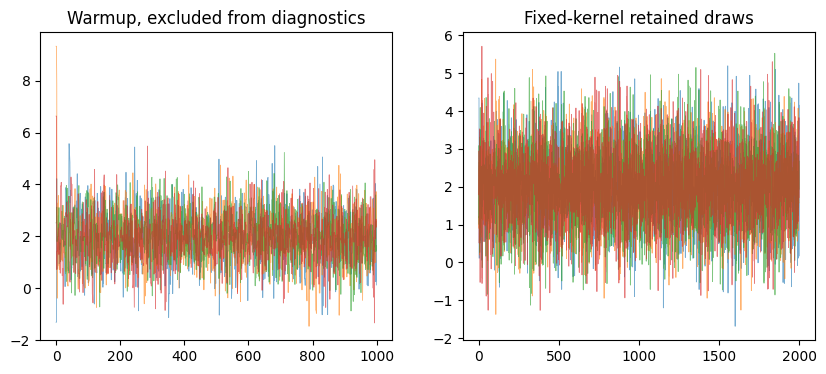

In [3]:
rows=pd.read_csv(ROOT/"docs/sampling_comparison.csv")
display(rows[(rows.target=="gaussian")&rows.method.isin(["hmc","adaptive_hmc","nuts"])][["method","profile","max_rhat","min_bulk_ess","divergences"]])
data=numeric("gaussian_adaptive_hmc_dispersed_0.1")
assert all(np.unique(s).size==1 for s in data["step_size"])
fig,axes=plt.subplots(1,2,figsize=(10,4))
for i in range(4):
 axes[0].plot(data["warmup"][i,:,0],lw=.6,alpha=.6)
 axes[1].plot(data["samples"][i,:,0],lw=.6,alpha=.6)
axes[0].set(title="Warmup, excluded from diagnostics");axes[1].set(title="Fixed-kernel retained draws");plt.show()

## Interpretation and next step

Read the [theory](../docs/theory.md), [diagnostic scope](../docs/diagnostics.md), and [data protocol](../docs/data_and_protocols.md). Change one declared preset in a separate output directory; keep warmup, test evaluation and model selection distinct. The [interactive explorer](../docs/explorer.html) exposes the complete recorded comparisons.